In [1]:

from pathlib import Path
from collections import Counter
import pandas as pd

# Project root (works from project root or notebooks/)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = (
    PROJECT_ROOT / "data" / "beach_bird"
    / "Beach Bird Detection Dataset v1.0"
)

records = []

for split in ["train", "val"]:
    label_files = sorted((DATASET_ROOT / "labels" / split).glob("*.txt"))
    bird_counts = []
    class_counts = Counter()

    for file in label_files:
        lines = [line for line in file.read_text().splitlines()
                 if line.strip()]

        bird_counts.append(len(lines))

        for line in lines:
            class_counts[int(line.split()[0])] += 1

    records.append({
        "Split": split,
        "Images": len(label_files),
        "Total Objects": sum(bird_counts),
        "Avg Objects/Image": round(sum(bird_counts) / len(label_files), 2),
        "Max Objects": max(bird_counts),
        "Empty Annotations": bird_counts.count(0),
        "Class Distribution": dict(class_counts),
    })

df = pd.DataFrame(records)
display(df)


,Split,Images,Total Objects,Avg Objects/Image,Max Objects,Empty Annotations,Class Distribution
0,train,1369,8663,6.33,130,154,{0: 8663}
1,val,291,1843,6.33,100,33,{0: 1843}


count    1369.000000
mean        6.327977
std         9.725687
min         0.000000
50%         3.000000
75%         7.000000
90%        15.000000
95%        24.000000
99%        44.640000
max       130.000000
dtype: float64


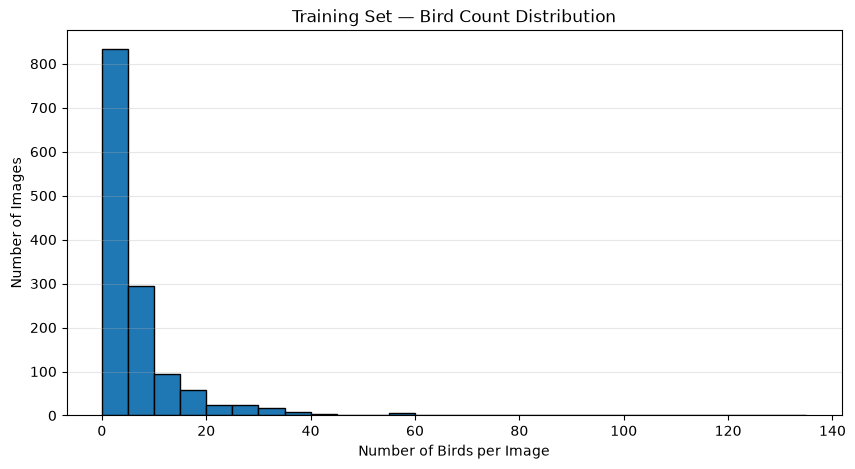

In [2]:

import matplotlib.pyplot as plt
import pandas as pd

# Count birds in each training image
label_dir = DATASET_ROOT / "labels" / "train"

bird_counts = []

for file in sorted(label_dir.glob("*.txt")):
    lines = [
        line for line in file.read_text().splitlines()
        if line.strip()
    ]
    bird_counts.append(len(lines))

# Summary statistics
counts = pd.Series(bird_counts)

print(counts.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

# Plot histogram
plt.figure(figsize=(10, 5))
plt.hist(bird_counts, bins=range(0, 136, 5),
         edgecolor="black")

plt.xlabel("Number of Birds per Image")
plt.ylabel("Number of Images")
plt.title("Training Set — Bird Count Distribution")
plt.grid(axis="y", alpha=0.3)

plt.show()


Bounding Box Area (% of image)
count    8663.000000
mean        2.909155
std         6.873764
min         0.008217
10%         0.108503
25%         0.269062
50%         0.718194
75%         2.640296
90%         6.919768
99%        34.539066
max        93.028400
dtype: float64


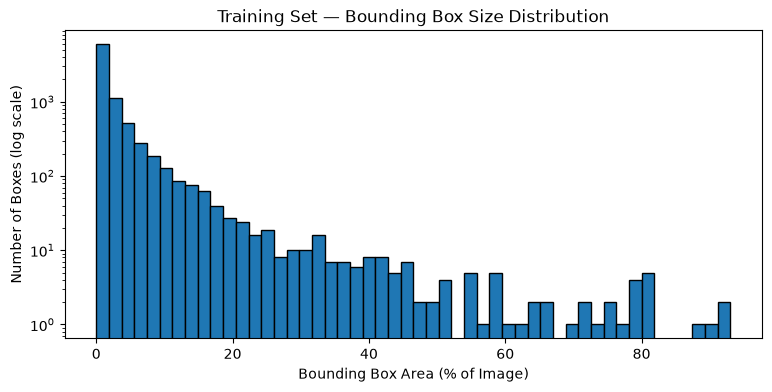

In [3]:

# Bounding Box Size Analysis
box_areas = []

for file in sorted((DATASET_ROOT / "labels" / "train").glob("*.txt")):
    for line in file.read_text().splitlines():
        if not line.strip():
            continue

        cls, x, y, w, h = map(float, line.split())

        # Percentage of image area occupied by the box
        area_percent = w * h * 100
        box_areas.append(area_percent)

areas = pd.Series(box_areas)

print("Bounding Box Area (% of image)")
print(areas.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

plt.figure(figsize=(9, 4))
plt.hist(areas, bins=50, edgecolor="black")
plt.yscale("log")
plt.xlabel("Bounding Box Area (% of Image)")
plt.ylabel("Number of Boxes (log scale)")
plt.title("Training Set — Bounding Box Size Distribution")
plt.show()



## Research Questions — Detection Difficulty Analysis

### RQ1: Object Size
How does bird size affect detection performance?

### RQ2: Object Density
Do YOLO and RT-DETR perform differently in dense flocks?

### RQ3: Background Similarity
Does low foreground-background contrast increase missed detections?

### RQ4: Scale and Appearance Variation
How robust are the models to variations in size,
pose, lighting, and image quality?

### RQ5: Model Architecture
How do CNN-based YOLO and Transformer-based RT-DETR
differ in their detection failures?

### Research Strategy
1. Characterise training and validation data.
2. Establish model baselines.
3. Analyse performance across difficulty factors.
4. Propose targeted improvements.
5. Evaluate improvements using controlled experiments.

### Evaluation Rules
- Use training data for model fitting.
- Use validation data for development and analysis.
- Keep the test set for final evaluation.
- Report mAP@0.5, recall, and inference time.


In [4]:

from PIL import Image
from collections import Counter

image_dir = DATASET_ROOT / "images" / "train"
label_dir = DATASET_ROOT / "labels" / "train"

# Match images with their annotations
images = {
    p.stem: p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

size_counts = Counter()

for label_file in label_dir.glob("*.txt"):
    image_path = images.get(label_file.stem)
    if image_path is None:
        raise FileNotFoundError(label_file.stem)

    with Image.open(image_path) as image:
        W, H = image.size

    for line in label_file.read_text().splitlines():
        if not line.strip():
            continue

        _, xc, yc, w, h = map(float, line.split())

        # Original pixel area
        area = (w * W) * (h * H)

        if area < 32**2:
            size_counts["Small"] += 1
        elif area < 96**2:
            size_counts["Medium"] += 1
        else:
            size_counts["Large"] += 1

total = sum(size_counts.values())

for category in ["Small", "Medium", "Large"]:
    n = size_counts[category]
    print(f"{category}: {n} ({n / total * 100:.2f}%)")


Small: 2978 (34.38%)
Medium: 3973 (45.86%)
Large: 1712 (19.76%)


Spearman correlation: -0.562


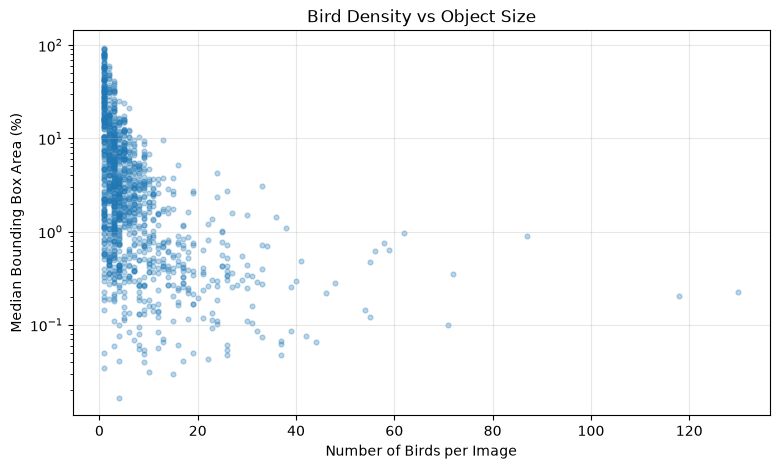

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

records = []

for file in sorted((DATASET_ROOT / "labels" / "train").glob("*.txt")):
    areas = []

    for line in file.read_text().splitlines():
        if not line.strip():
            continue

        cls, xc, yc, w, h = map(float, line.split())
        areas.append(w * h * 100)

    if areas:
        records.append({
            "bird_count": len(areas),
            "median_area": np.median(areas)
        })

density_df = pd.DataFrame(records)

# Spearman rank correlation
correlation = density_df["bird_count"].corr(
    density_df["median_area"],
    method="spearman"
)

print(f"Spearman correlation: {correlation:.3f}")

plt.figure(figsize=(9, 5))
plt.scatter(
    density_df["bird_count"],
    density_df["median_area"],
    alpha=0.3,
    s=12
)

plt.yscale("log")
plt.xlabel("Number of Birds per Image")
plt.ylabel("Median Bounding Box Area (%)")
plt.title("Bird Density vs Object Size")
plt.grid(alpha=0.3)
plt.show()


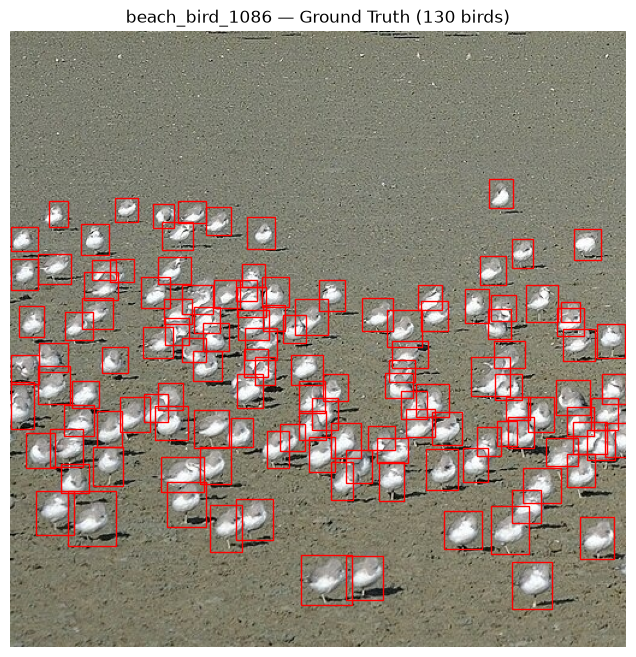

In [6]:

from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

# Find the training image with the most birds
label_dir = DATASET_ROOT / "labels" / "train"
image_dir = DATASET_ROOT / "images" / "train"

label_files = list(label_dir.glob("*.txt"))
densest = max(
    label_files,
    key=lambda p: len(p.read_text().splitlines())
)

# Find corresponding image
image_path = next(
    p for p in image_dir.iterdir()
    if p.stem == densest.stem
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

image = Image.open(image_path).convert("RGB")
W, H = image.size

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for line in densest.read_text().splitlines():
    cls, xc, yc, w, h = map(float, line.split())

    x = (xc - w / 2) * W
    y = (yc - h / 2) * H

    rect = Rectangle(
        (x, y), w * W, h * H,
        fill=False, edgecolor="red", linewidth=1
    )
    ax.add_patch(rect)

ax.set_title(f"{densest.stem} — Ground Truth ({len(densest.read_text().splitlines())} birds)")
ax.axis("off")
plt.show()
